In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path 
DATA_PATH = str(Path.cwd() / "data") + "/"

training_data = pd.read_csv(
    DATA_PATH + "train.csv",
    parse_dates=["date"]
)

test = pd.read_csv(
    DATA_PATH + "test.csv",
    parse_dates=["date"]
)

stores = pd.read_csv(DATA_PATH + "stores.csv")

oil = pd.read_csv(
    DATA_PATH + "oil.csv",
    parse_dates=["date"]
)

holidays = pd.read_csv(
    DATA_PATH + "holidays_events.csv",
    parse_dates=["date"]
)

In [2]:
grocery = training_data[training_data['family'] == 'GROCERY I'].copy()
grocery_daily = grocery.groupby('date')['sales'].sum()
grocery['year'] = grocery['date'].dt.year
grocery['month'] = grocery['date'].dt.month
grocery['day'] = grocery['date'].dt.day
grocery['dayofweek'] = grocery['date'].dt.dayofweek  # 0=Monday, 6=Sunday
grocery['is_weekend'] = (grocery['dayofweek'] >= 5).astype(int)  # 1 if weekend
grocery['day_of_year'] = grocery['date'].dt.dayofyear

Lag Features:
         date     sales  sales_lag_1  sales_lag_7  sales_lag_14
0  2013-01-01     700.0          NaN          NaN           NaN
1  2013-01-02  202020.0        700.0          NaN           NaN
2  2013-01-03  144878.0     202020.0          NaN           NaN
3  2013-01-04  135754.0     144878.0          NaN           NaN
4  2013-01-05  188356.0     135754.0          NaN           NaN
5  2013-01-06  207297.0     188356.0          NaN           NaN
6  2013-01-07  133189.0     207297.0          NaN           NaN
7  2013-01-08  133290.0     133189.0        700.0           NaN
8  2013-01-09  115871.0     133290.0     202020.0           NaN
9  2013-01-10   96200.0     115871.0     144878.0           NaN
10 2013-01-11  103280.0      96200.0     135754.0           NaN
11 2013-01-12  151025.0     103280.0     188356.0           NaN
12 2013-01-13  183099.0     151025.0     207297.0           NaN
13 2013-01-14  112128.0     183099.0     133189.0           NaN
14 2013-01-15  114578.0   

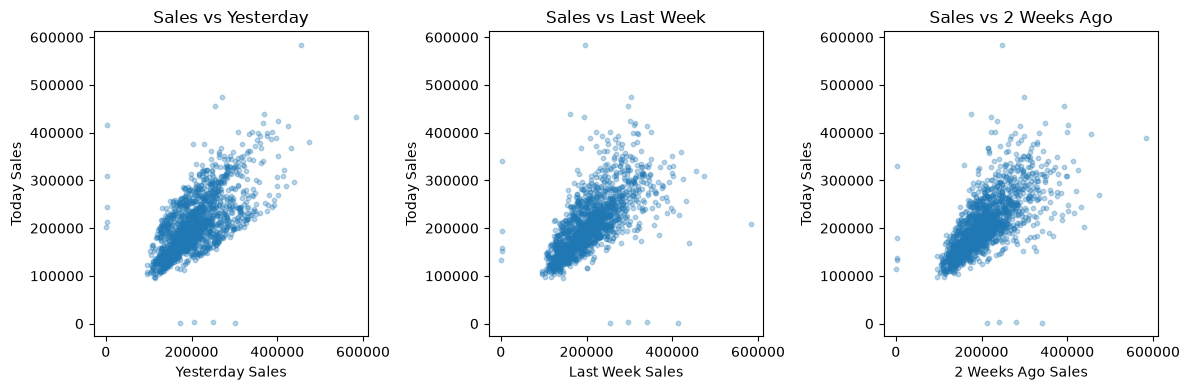

In [3]:

daily_sales = grocery.groupby('date')['sales'].sum().reset_index()
daily_sales = daily_sales.sort_values('date')

daily_sales['sales_lag_1'] = daily_sales['sales'].shift(1)   # yesterday
daily_sales['sales_lag_7'] = daily_sales['sales'].shift(7)   # same day as last week
daily_sales['sales_lag_14'] = daily_sales['sales'].shift(14) # two week prior 

print("Lag Features:")
print(daily_sales[['date', 'sales', 'sales_lag_1', 'sales_lag_7', 'sales_lag_14']].head(20))

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.scatter(daily_sales['sales_lag_1'], daily_sales['sales'], alpha=0.3, s=10)
plt.xlabel('Yesterday Sales')
plt.ylabel('Today Sales')
plt.title('Sales vs Yesterday')

plt.subplot(1, 3, 2)
plt.scatter(daily_sales['sales_lag_7'], daily_sales['sales'], alpha=0.3, s=10)
plt.xlabel('Last Week Sales')
plt.ylabel('Today Sales')
plt.title('Sales vs Last Week')

plt.subplot(1, 3, 3)
plt.scatter(daily_sales['sales_lag_14'], daily_sales['sales'], alpha=0.3, s=10)
plt.xlabel('2 Weeks Ago Sales')
plt.ylabel('Today Sales')
plt.title('Sales vs 2 Weeks Ago')

plt.tight_layout()
plt.show()

Rolling Features:
           date       sales  rolling_mean_7  rolling_mean_14  rolling_std_7
1664 2017-07-27  196079.180   234937.628286    235352.829929   36294.319663
1665 2017-07-28  233685.813   233986.571714    236307.808786   37350.603551
1666 2017-07-29  303657.532   236287.837571    238000.313286   36660.945565
1667 2017-07-30  328519.734   241220.878714    239952.761214   43501.187924
1668 2017-07-31  270215.666   245624.884000    241340.988714   51072.644477
1669 2017-08-01  301453.492   249842.655571    243398.035214   51811.081290
1670 2017-08-02  281631.338   262766.580714    249792.987786   51786.378481
1671 2017-08-03  227658.804   273606.107857    254271.868071   45412.966452
1672 2017-08-04  244474.234   278117.482714    256052.027214   37265.461666
1673 2017-08-05  292312.398   279658.685714    257973.261643   35292.481642
1674 2017-08-06  314408.414   278037.952286    259629.415500   34251.861109
1675 2017-08-07  244548.234   276022.049429    260823.466714   31051.2

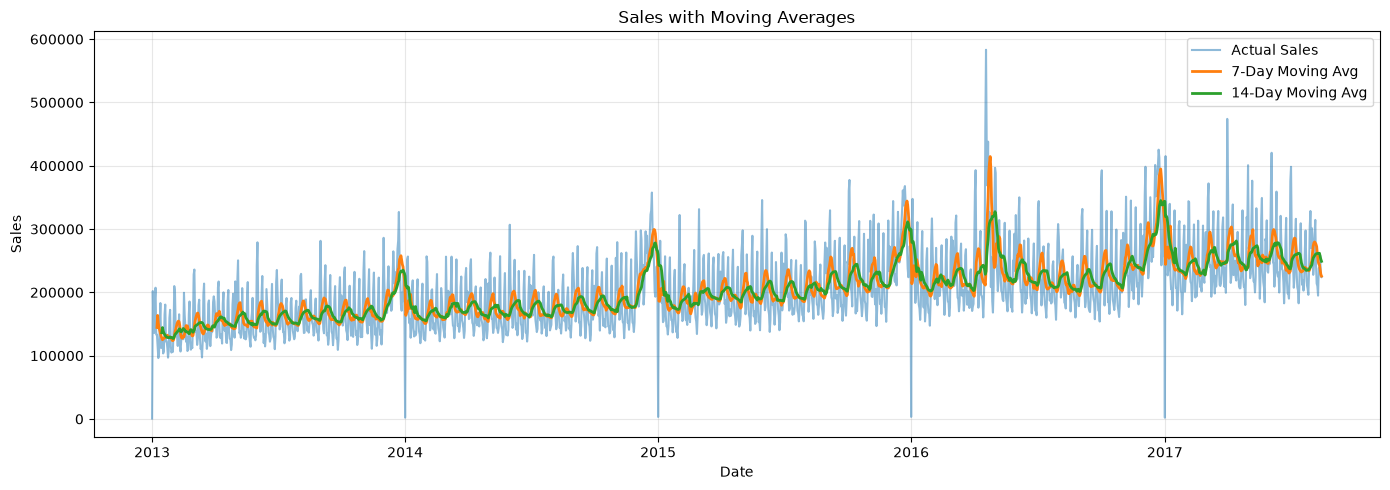

In [4]:
daily_sales['rolling_mean_7'] = daily_sales['sales'].shift(1).rolling(window=7).mean()

daily_sales['rolling_mean_14'] = daily_sales['sales'].shift(1).rolling(window=14).mean()

daily_sales['rolling_std_7'] = daily_sales['sales'].shift(1).rolling(window=7).std()

print("Rolling Features:")
print(daily_sales[['date', 'sales', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7']].tail(20))


plt.figure(figsize=(14, 5))
plt.plot(daily_sales['date'], daily_sales['sales'], label='Actual Sales', alpha=0.5)
plt.plot(daily_sales['date'], daily_sales['rolling_mean_7'], label='7-Day Moving Avg', linewidth=2)
plt.plot(daily_sales['date'], daily_sales['rolling_mean_14'], label='14-Day Moving Avg', linewidth=2)
plt.title('Sales with Moving Averages')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

合并oil price后:
        date     sales  dcoilwtico
0 2013-01-01     700.0         NaN
1 2013-01-02  202020.0       93.14
2 2013-01-03  144878.0       92.97
3 2013-01-04  135754.0       93.12
4 2013-01-05  188356.0         NaN
5 2013-01-06  207297.0         NaN
6 2013-01-07  133189.0       93.20
7 2013-01-08  133290.0       93.21
8 2013-01-09  115871.0       93.08
9 2013-01-10   96200.0       93.81


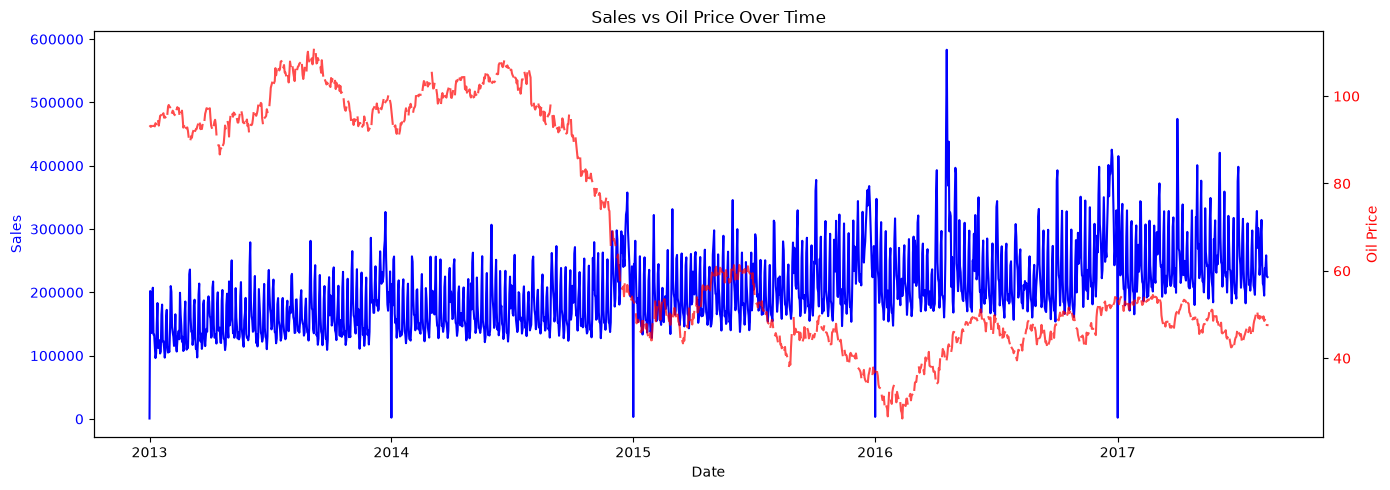

In [5]:
oil_clean = oil.copy()
oil_clean['dcoilwtico'] = oil_clean['dcoilwtico'].interpolate(method='linear')

daily_sales = daily_sales.merge(oil_clean, on='date', how='left')

print("合并oil price后:")
print(daily_sales[['date', 'sales', 'dcoilwtico']].head(10))

fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(daily_sales['date'], daily_sales['sales'], color='blue', label='Sales')
ax1.set_xlabel('Date')
ax1.set_ylabel('Sales', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.plot(daily_sales['date'], daily_sales['dcoilwtico'], color='red', alpha=0.7, label='Oil Price')
ax2.set_ylabel('Oil Price', color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title('Sales vs Oil Price Over Time')
plt.tight_layout()
plt.show()

In [6]:
correlation = daily_sales[['sales', 'dcoilwtico']].corr()
print(correlation)

               sales  dcoilwtico
sales       1.000000   -0.564923
dcoilwtico -0.564923    1.000000


# Auto-ARIMA Forecasting and Validation

In [7]:
from pmdarima import auto_arima
import warnings

warnings.filterwarnings("ignore")

# Features available for the entire forecast period
FEATURE_COLUMNS = [
    'total_promotions',
    'dayofweek',
    'is_weekend'
]


In [8]:
def build_family_daily(family_name, training_data, oil_clean):
    # Select training data for one product family
    fam = training_data[
        training_data['family'] == family_name
    ].copy()

    # Aggregate daily sales
    daily = (
        fam.groupby('date')['sales']
        .sum()
        .reset_index()
        .sort_values('date')
        .reset_index(drop=True)
    )

    # Aggregate daily promotions
    promo = (
        fam.groupby('date')['onpromotion']
        .sum()
        .reset_index()
        .rename(columns={
            'onpromotion': 'total_promotions'
        })
    )

    daily = daily.merge(
        promo,
        on='date',
        how='left'
    )

    daily['total_promotions'] = (
        daily['total_promotions'].fillna(0)
    )

    # Calendar features
    daily['dayofweek'] = daily['date'].dt.dayofweek

    daily['is_weekend'] = (
        daily['dayofweek'] >= 5
    ).astype(int)

    return daily.reset_index(drop=True)




def fit_sarima(y_train, X_train):
    if y_train.sum() == 0:
        return None

    model = auto_arima(
        y_train,
        X=X_train,
        seasonal=True,
        m=7,
        stepwise=True,
        information_criterion='aic',
        suppress_warnings=True,
        error_action='ignore'
    )

    return model


def build_test_exog(family_name, training_data, test, oil_clean):
    # Select test data for this product family
    test_fam = test[test['family'] == family_name].copy()

    # Get unique forecast dates
    test_dates = sorted(test_fam['date'].unique())
    test_exog = pd.DataFrame({'date': test_dates})

    # Promotions are available in the Kaggle test dataset
    promo = test_fam.groupby('date')['onpromotion'].sum().reset_index()
    promo.columns = ['date', 'total_promotions']
    test_exog = test_exog.merge(promo, on='date', how='left')
    test_exog['total_promotions'] = test_exog['total_promotions'].fillna(0)

    # Calendar features
    test_exog['dayofweek'] = pd.to_datetime(test_exog['date']).dt.dayofweek
    test_exog['is_weekend'] = (test_exog['dayofweek'] >= 5).astype(int)

    # Return features in the same order as training
    return test_exog[['date'] + FEATURE_COLUMNS].reset_index(drop=True)
  

In [9]:
n_test_days = test['date'].nunique()
families = sorted(test['family'].unique())

family_forecasts = {}
failed_families = []

In [10]:

from sklearn.metrics import mean_squared_error
import numpy as np

# Prepare historical data
daily = build_family_daily(
    'GROCERY I',
    training_data,
    None
)

# Reserve the final 16 days for validation
train_subset = daily.iloc[:-16].copy()
validation = daily.iloc[-16:].copy()

y_train_val = train_subset['sales']
X_train_val = train_subset[FEATURE_COLUMNS]

y_val = validation['sales']
X_val = validation[FEATURE_COLUMNS]

# Train using historical data only
print("Training validation model...")

validation_model = fit_sarima(
    y_train_val,
    X_train_val
)

# Forecast the next 16 days
predictions = validation_model.predict(
    n_periods=len(validation),
    X=X_val
)

predictions = np.maximum(
    np.asarray(predictions),
    0
)

# Calculate model RMSE
model_rmse = np.sqrt(
    mean_squared_error(y_val, predictions)
)

# Fixed-origin seasonal baseline
# Repeat the final 7 known days for the 16-day forecast

last_7_sales = train_subset['sales'].iloc[-7:].to_numpy()

baseline_predictions = np.tile(
    last_7_sales,
    int(np.ceil(len(validation) / 7))
)[:len(validation)]

baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_predictions)
)

improvement = (
    (baseline_rmse - model_rmse) / baseline_rmse
) * 100

print("\nValidation Results:")
print(f"Auto-ARIMA RMSE: {model_rmse:,.2f}")
print(f"Baseline RMSE: {baseline_rmse:,.2f}")
print(f"Improvement: {improvement:.2f}%")


Training validation model...

Validation Results:
Auto-ARIMA RMSE: 37,880.70
Baseline RMSE: 40,209.50
Improvement: 5.79%


Image saved to: /Users/tonychen/Documents/programing/Time Series Forcasting /images/grocery_forecast_validation.png


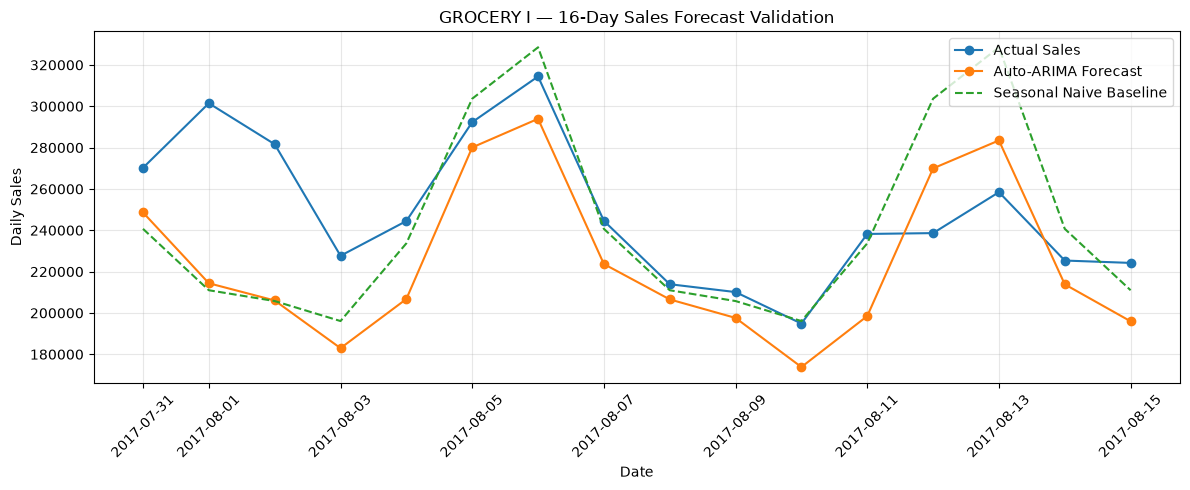

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    validation['date'],
    y_val.to_numpy(),
    marker='o',
    label='Actual Sales'
)

plt.plot(
    validation['date'],
    predictions,
    marker='o',
    label='Auto-ARIMA Forecast'
)

plt.plot(
    validation['date'],
    baseline_predictions,
    linestyle='--',
    label='Seasonal Naive Baseline'
)

plt.title('GROCERY I — 16-Day Sales Forecast Validation')
plt.xlabel('Date')
plt.ylabel('Daily Sales')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

from pathlib import Path


output_dir = Path(DATA_PATH).parent / "images"


output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "grocery_forecast_validation.png",
    dpi=200,
    bbox_inches="tight"
)

print("Image saved to:", output_dir / "grocery_forecast_validation.png")

plt.show()

In [12]:
for i, family in enumerate(families):
    # prepare data
    daily = build_family_daily(family, training_data, None)
    X_all = daily[FEATURE_COLUMNS]
    y_all = daily['sales']
    
    # fit and train model
    fit = fit_sarima(y_all, X_all)
    
    if fit is None:
        # Fallback: repeat last week
        tail = y_all.tail(7).values
        fallback = np.tile(tail, 3)[:n_test_days]
        family_forecasts[family] = fallback
        failed_families.append(family)
        print('FALLBACK (zero sales or fit error)')
        continue
    
    # Build test exog features
    test_exog_df = build_test_exog(family, training_data, test, None)
    X_test_fc    = test_exog_df[FEATURE_COLUMNS]
    
    pred = fit.predict(
    n_periods=n_test_days,
    X=X_test_fc
    )
    family_forecasts[family] = np.maximum(pred, 0)  # clip negatives
    print('Forecast completed for ', family, ". Progress: ", str(i+1), "/33")
    
print(f'\nCompleted: {len(families) - len(failed_families)}/{len(families)} Auto-ARIMA fits succeeded')
if failed_families:
    print(f'Fallback used for: {failed_families}')

Forecast completed for  AUTOMOTIVE . Progress:  1 /33
Forecast completed for  BABY CARE . Progress:  2 /33
Forecast completed for  BEAUTY . Progress:  3 /33
Forecast completed for  BEVERAGES . Progress:  4 /33
Forecast completed for  BOOKS . Progress:  5 /33
Forecast completed for  BREAD/BAKERY . Progress:  6 /33
Forecast completed for  CELEBRATION . Progress:  7 /33
Forecast completed for  CLEANING . Progress:  8 /33
Forecast completed for  DAIRY . Progress:  9 /33
Forecast completed for  DELI . Progress:  10 /33
Forecast completed for  EGGS . Progress:  11 /33
Forecast completed for  FROZEN FOODS . Progress:  12 /33
Forecast completed for  GROCERY I . Progress:  13 /33
Forecast completed for  GROCERY II . Progress:  14 /33
Forecast completed for  HARDWARE . Progress:  15 /33
Forecast completed for  HOME AND KITCHEN I . Progress:  16 /33
Forecast completed for  HOME AND KITCHEN II . Progress:  17 /33
Forecast completed for  HOME APPLIANCES . Progress:  18 /33
Forecast completed for  H

In [13]:
# ── Compute store-level shares and build submission.csv ──────────────────────

# Historical share of each store within each family (full training period)
store_sales   = training_data.groupby(['family', 'store_nbr'])['sales'].sum().reset_index()
family_totals = store_sales.groupby('family')['sales'].transform('sum')
store_sales['share'] = store_sales['sales'] / family_totals.replace(0, 1)

print(f'Store shares computed: {len(store_sales)} (family, store) pairs')

# Build a long-form (family, date, family_forecast) DataFrame
test_dates_sorted = sorted(test['date'].unique())

fc_records = []
for family, forecasts in family_forecasts.items():
    for date, pred in zip(test_dates_sorted, forecasts):
        fc_records.append({'family': family, 'date': date, 'family_forecast': float(pred)})

fc_df = pd.DataFrame(fc_records)

# Join test.csv (authoritative list of ids) with forecasts and store shares
sub = test[['id', 'date', 'store_nbr', 'family']].copy()
sub = sub.merge(fc_df, on=['family', 'date'], how='left')
sub = sub.merge(store_sales[['family', 'store_nbr', 'share']],
                on=['family', 'store_nbr'], how='left')

sub['sales'] = (sub['family_forecast'] * sub['share']).clip(lower=0).fillna(0)

submission = sub[['id', 'sales']].sort_values('id').reset_index(drop=True)

# Sanity checks
print(f'\nSubmission shape : {submission.shape}  (expected (28512, 2))')
print(f'Missing sales    : {submission["sales"].isna().sum()}')
print(f'Negative sales   : {(submission["sales"] < 0).sum()}')
print(f'Total forecast   : {submission["sales"].sum():,.0f}')
print('\nSample rows:')
print(submission.head(10))

submission.to_csv('submission.csv', index=False)
print('\nSaved: submission.csv')


Store shares computed: 1782 (family, store) pairs

Submission shape : (28512, 2)  (expected (28512, 2))
Missing sales    : 0
Negative sales   : 0
Total forecast   : 13,187,555

Sample rows:
        id        sales
0  3000888     3.100223
1  3000889     0.000000
2  3000890     5.630250
3  3000891  2232.487026
4  3000892     0.000000
5  3000893   389.647648
6  3000894    13.027195
7  3000895   706.609724
8  3000896   778.788589
9  3000897   128.016226

Saved: submission.csv


In [14]:
print("Submission shape:", submission.shape)
print("Expected shape:", (len(test), 2))
print("Missing predictions:", submission["sales"].isna().sum())
print("Negative predictions:", (submission["sales"] < 0).sum())
print("Duplicate IDs:", submission["id"].duplicated().sum())

assert len(submission) == len(test)
assert submission["id"].nunique() == test["id"].nunique()
assert submission["sales"].notna().all()
assert (submission["sales"] >= 0).all()

print("✓ Submission validation passed")
submission.head()

Submission shape: (28512, 2)
Expected shape: (28512, 2)
Missing predictions: 0
Negative predictions: 0
Duplicate IDs: 0
✓ Submission validation passed


,id,sales
0,3000888,3.100223
1,3000889,0.000000
2,3000890,5.630250
3,3000891,2232.487026
4,3000892,0.000000


In [17]:

# Final Kaggle submission validation

print("Submission shape:", submission.shape)
print("Expected rows:", len(test))

print("\nMissing values:")
print(submission.isna().sum())

print("\nNegative predictions:",
      (submission['sales'] < 0).sum())

print("\nDuplicate IDs:",
      submission['id'].duplicated().sum())

assert len(submission) == len(test)
assert submission['sales'].notna().all()
assert (submission['sales'] >= 0).all()
assert not submission['id'].duplicated().any()

print("\nAll submission checks passed!")
print("Failed families:", failed_families)


Submission shape: (28512, 2)
Expected rows: 28512

Missing values:
id       0
sales    0
dtype: int64

Negative predictions: 0

Duplicate IDs: 0

All submission checks passed!
Failed families: []
